# Laboratory Work No. 2. Cross-Validation Techniques

**Task:** Apply at least five cross-validation schemes to the data from Lab 1 and compare the results.

**Model:** Linear Regression.

**Target variable:** Next-day Bitcoin closing price:

$$
y_t = Close_{t+1}.
$$

The last 20% of observations are reserved as a separate out-of-time test set and are not included in cross-validation.

In [1]:
%pip install -q kagglehub pandas numpy scikit-learn matplotlib seaborn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try brew install
    xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a Python library that isn't in Homebrew,
    use a virtual environment:
    
    python3 -m venv path/to/venv
    source path/to/venv/bin/activate
    python3 -m pip install xyz
    
    If you wish to install a Python application that isn't in Homebrew,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. You can install pipx with
    
    brew install pipx
    
    You may restore the old behavior of pip by passing
    the '--break-system-packages' flag to pip, or by adding
    'break-system-packages = true' to your pip.conf file. The latter
    will permanently disable this error.
    
    If you disable this error, we STRONGLY recommend that you additionally
    pass the '--user' flag to pip, or set 

In [ ]:
from pathlib import Path
import re
import warnings

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    KFold,
    ShuffleSplit,
    GroupKFold,
    TimeSeriesSplit,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
N_SPLITS = 5

## 1. Data Loading and Preparation

The same dataset as in Lab 1 is used.

In [3]:
path = kagglehub.dataset_download("amineipad/bitcoin-prices-dataset")
dataset_dir = Path(path)

ALIASES = {
    "Date": {"date", "datetime", "timestamp", "time"},
    "Open": {"open", "openprice", "24open"},
    "High": {"high", "highprice", "24high"},
    "Low": {"low", "lowprice", "24low"},
    "Close": {"close", "closingprice", "price", "lastprice"},
    "Volume": {"volume", "vol", "volumebtc", "volumeusd", "tradevolume"},
}

def normalize_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).strip().lower())

def find_column_map(columns):
    normalized = {normalize_name(col): col for col in columns}
    mapping = {}
    for target, aliases in ALIASES.items():
        for alias in aliases:
            if alias in normalized:
                mapping[target] = normalized[alias]
                break
    return mapping

def parse_numeric(series):
    s = series.astype(str).str.strip()
    s = s.str.replace(",", "", regex=False)
    s = s.str.replace("$", "", regex=False)
    suffix = s.str.extract(r"([KMBT])$", expand=False)
    multipliers = suffix.map({"K": 1e3, "M": 1e6, "B": 1e9, "T": 1e12}).fillna(1.0)
    s = s.str.replace(r"[KMBT]$", "", regex=True)
    values = pd.to_numeric(s, errors="coerce")
    return values * multipliers

selected_file = None
column_map = None

for csv_file in sorted(dataset_dir.rglob("*.csv")):
    try:
        sample = pd.read_csv(csv_file, nrows=10)
    except Exception:
        continue

    mapping = find_column_map(sample.columns)
    if set(ALIASES).issubset(mapping):
        selected_file = csv_file
        column_map = mapping
        break

if selected_file is None:
    raise FileNotFoundError(
        "No CSV file with fields Date, Open, High, Low, Close, and Volume was found in the downloaded dataset."
    )

raw = pd.read_csv(selected_file)

df = pd.DataFrame({
    "Date": raw[column_map["Date"]],
    "Open": raw[column_map["Open"]],
    "High": raw[column_map["High"]],
    "Low": raw[column_map["Low"]],
    "Close": raw[column_map["Close"]],
    "Volume": raw[column_map["Volume"]],
})

if pd.api.types.is_numeric_dtype(df["Date"]):
    median_timestamp = pd.to_numeric(df["Date"], errors="coerce").dropna().median()
    unit = "ms" if median_timestamp > 1e11 else "s"
    df["Date"] = pd.to_datetime(df["Date"], unit=unit, errors="coerce")
else:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=False)

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = parse_numeric(df[col])

df = (
    df.dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])
      .drop_duplicates(subset="Date", keep="last")
      .sort_values("Date")
      .reset_index(drop=True)
)

valid_ohlc = (
    (df["Open"] > 0)
    & (df["High"] > 0)
    & (df["Low"] > 0)
    & (df["Close"] > 0)
    & (df["Volume"] >= 0)
    & (df["High"] >= df[["Open", "Low", "Close"]].max(axis=1))
    & (df["Low"] <= df[["Open", "High", "Close"]].min(axis=1))
)

df = df.loc[valid_ohlc].reset_index(drop=True)

print("File:", selected_file.name)
print("Data shape:", df.shape)
print("Period:", df["Date"].min().date(), "—", df["Date"].max().date())
df.head()

File: bitcoin.csv
Data shape: (5883, 6)
Period: 2010-01-01 — 2026-02-08


,Date,Open,High,Low,Close,Volume
0,2010-01-01,0.3,0.303428,0.295510,0.3,715.8
1,2010-01-02,0.3,0.304377,0.299459,0.3,2028.3
2,2010-01-03,0.3,0.303736,0.295858,0.3,273.0
3,2010-01-04,0.3,0.303406,0.298489,0.3,1452.0
4,2010-01-05,0.3,0.302715,0.296330,0.3,1002.6


## 2. Feature and Target Variable Engineering

Only data known by the end of day $t$ is used to forecast $Close_{t+1}$.

In [4]:
model_df = df.copy()

model_df["LogVolume"] = np.log1p(model_df["Volume"])
model_df["LogReturn_1d"] = np.log(model_df["Close"] / model_df["Close"].shift(1))
model_df["RangePct"] = (model_df["High"] - model_df["Low"]) / model_df["Close"]
model_df["SMA_7"] = model_df["Close"].rolling(7).mean()
model_df["SMA_30"] = model_df["Close"].rolling(30).mean()

model_df["Target_Close_Next_Day"] = model_df["Close"].shift(-1)
model_df["TargetDate"] = model_df["Date"].shift(-1)

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close",
    "LogVolume",
    "LogReturn_1d",
    "RangePct",
    "SMA_7",
    "SMA_30",
]
TARGET = "Target_Close_Next_Day"

model_df = (
    model_df.dropna(subset=FEATURES + [TARGET, "TargetDate"])
            .reset_index(drop=True)
)

split_idx = int(len(model_df) * 0.80)
split_target_date = model_df.loc[split_idx - 1, "TargetDate"]

dev = model_df[model_df["TargetDate"] <= split_target_date].copy().reset_index(drop=True)
holdout = model_df[model_df["TargetDate"] > split_target_date].copy().reset_index(drop=True)

X_dev = dev[FEATURES]
y_dev = dev[TARGET]

X_holdout = holdout[FEATURES]
y_holdout = holdout[TARGET]

print("Development:", len(dev), "observations")
print("Hold-out:", len(holdout), "observations")
print("Development target period:", dev["TargetDate"].min().date(), "—", dev["TargetDate"].max().date())
print("Hold-out target period:", holdout["TargetDate"].min().date(), "—", holdout["TargetDate"].max().date())

Development: 4682 observations
Hold-out: 1171 observations
Development target period: 2010-01-31 — 2022-11-25
Hold-out target period: 2022-11-26 — 2026-02-08


## 3. Model and Cross-Validation Schemes

Six schemes are compared:

1. `KFold` without shuffling;
2. `KFold` with shuffling;
3. `ShuffleSplit`;
4. `GroupKFold` by year;
5. `TimeSeriesSplit`;
6. `BlockingTimeSeriesSplit`.

The same model is used for all variants: `StandardScaler + LinearRegression`.

In [5]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

class BlockingTimeSeriesSplit(BaseEstimator):
    def __init__(self, n_splits=5, train_ratio=0.8, gap=1):
        self.n_splits = n_splits
        self.train_ratio = train_ratio
        self.gap = gap

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

    def split(self, X, y=None, groups=None):
        n_samples = len(X)
        block_size = n_samples // self.n_splits
        indices = np.arange(n_samples)

        for i in range(self.n_splits):
            start = i * block_size
            stop = n_samples if i == self.n_splits - 1 else (i + 1) * block_size

            train_end = start + int((stop - start) * self.train_ratio)
            valid_start = train_end + self.gap

            train_idx = indices[start:train_end]
            valid_idx = indices[valid_start:stop]

            if len(train_idx) == 0 or len(valid_idx) == 0:
                continue

            yield train_idx, valid_idx

group_splits = min(N_SPLITS, dev["Date"].dt.year.nunique())

cv_methods = {
    "KFold without shuffle": KFold(
        n_splits=N_SPLITS,
        shuffle=False,
    ),
    "KFold with shuffle": KFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE,
    ),
    "ShuffleSplit": ShuffleSplit(
        n_splits=N_SPLITS,
        train_size=0.8,
        test_size=0.2,
        random_state=RANDOM_STATE,
    ),
    "GroupKFold by year": GroupKFold(
        n_splits=group_splits,
    ),
    "TimeSeriesSplit": TimeSeriesSplit(
        n_splits=N_SPLITS,
        gap=1,
    ),
    "BlockingTimeSeriesSplit": BlockingTimeSeriesSplit(
        n_splits=N_SPLITS,
        train_ratio=0.8,
        gap=1,
    ),
}

def get_splits(method_name):
    cv = cv_methods[method_name]
    if method_name == "GroupKFold by year":
        groups = dev["Date"].dt.year.to_numpy()
        return list(cv.split(X_dev, y_dev, groups=groups))
    return list(cv.split(X_dev, y_dev))

list(cv_methods.keys())

['KFold without shuffle',
 'KFold with shuffle',
 'ShuffleSplit',
 'GroupKFold by year',
 'TimeSeriesSplit',
 'BlockingTimeSeriesSplit']

## 4. Evaluation of Fold Performance

The `RMSE`, `MAE`, and $R^2$ metrics are used. For each scheme, the mean and standard deviation across folds are calculated.

In [6]:
fold_results = []

for method_name in cv_methods:
    splits = get_splits(method_name)

    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        fold_model = clone(model)

        X_train = X_dev.iloc[train_idx]
        y_train = y_dev.iloc[train_idx]
        X_valid = X_dev.iloc[valid_idx]
        y_valid = y_dev.iloc[valid_idx]

        fold_model.fit(X_train, y_train)
        pred = fold_model.predict(X_valid)

        rmse = mean_squared_error(y_valid, pred) ** 0.5
        mae = mean_absolute_error(y_valid, pred)
        r2 = r2_score(y_valid, pred)

        train_target_max = dev.iloc[train_idx]["TargetDate"].max()
        valid_feature_min = dev.iloc[valid_idx]["Date"].min()
        temporal_order_ok = train_target_max < valid_feature_min

        fold_results.append({
            "Method": method_name,
            "Fold": fold,
            "Train_size": len(train_idx),
            "Validation_size": len(valid_idx),
            "Train_start": dev.iloc[train_idx]["Date"].min(),
            "Train_end": dev.iloc[train_idx]["Date"].max(),
            "Validation_start": dev.iloc[valid_idx]["Date"].min(),
            "Validation_end": dev.iloc[valid_idx]["Date"].max(),
            "Temporal_order_ok": temporal_order_ok,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
        })

fold_results = pd.DataFrame(fold_results)
fold_results.head(10)

,Method,Fold,Train_size,Validation_size,Train_start,Train_end,Validation_start,Validation_end,Temporal_order_ok,RMSE,MAE,R2
0,KFold without shuffle,1,3745,937,2012-08-24,2022-11-24,2010-01-30,2012-08-23,False,30.542275,30.291477,-34.529720
1,KFold without shuffle,2,3745,937,2010-01-30,2022-11-24,2012-08-24,2015-03-18,False,35.110996,21.669444,0.982078
2,KFold without shuffle,3,3746,936,2010-01-30,2022-11-24,2015-03-19,2017-10-09,False,431.339192,26.456410,0.995114
3,KFold without shuffle,4,3746,936,2010-01-30,2022-11-24,2017-10-10,2020-05-02,False,797.908988,49.646359,0.990534
4,KFold without shuffle,5,3746,936,2010-01-30,2020-05-02,2020-05-03,2022-11-24,False,1124.866281,76.391964,0.992363
5,KFold with shuffle,1,3745,937,2010-01-30,2022-11-22,2010-02-07,2022-11-24,False,1113.700647,93.430160,0.993061
6,KFold with shuffle,2,3745,937,2010-01-31,2022-11-24,2010-01-30,2022-11-22,False,1124.389119,59.579564,0.993665
7,KFold with shuffle,3,3746,936,2010-01-30,2022-11-24,2010-02-17,2022-11-14,False,30.726506,19.137164,0.999995
8,KFold with shuffle,4,3746,936,2010-01-30,2022-11-24,2010-01-31,2022-11-16,False,34.098060,17.886257,0.999993
9,KFold with shuffle,5,3746,936,2010-01-30,2022-11-24,2010-02-02,2022-11-19,False,342.054748,31.370180,0.999418


In [7]:
summary = (
    fold_results.groupby("Method")
    .agg(
        Folds=("Fold", "count"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        Temporal_order_rate=("Temporal_order_ok", "mean"),
    )
    .reset_index()
)

summary["Temporal_order_rate"] *= 100
summary = summary.sort_values("RMSE_mean").reset_index(drop=True)

summary.round(4)

,Method,Folds,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Temporal_order_rate
0,KFold without shuffle,5,483.9535,479.3607,40.8911,22.5119,-6.113900e+00,1.588490e+01,0.0
1,BlockingTimeSeriesSplit,5,500.8748,1038.7387,107.3859,182.6861,-1.418419e+26,3.139826e+26,100.0
2,KFold with shuffle,5,528.9938,553.2893,44.2807,32.1919,9.972000e-01,3.500000e-03,0.0
3,TimeSeriesSplit,5,536.4786,518.8663,44.8135,39.7578,9.922000e-01,2.100000e-03,100.0
4,GroupKFold by year,5,545.7437,328.3816,37.4297,13.8026,8.592000e-01,2.982000e-01,0.0
5,ShuffleSplit,5,673.5441,445.7789,52.6016,28.0277,9.967000e-01,3.100000e-03,0.0


## 5. Visualization of Split Schemes

The plots display which observations are assigned to training and validation for each fold.

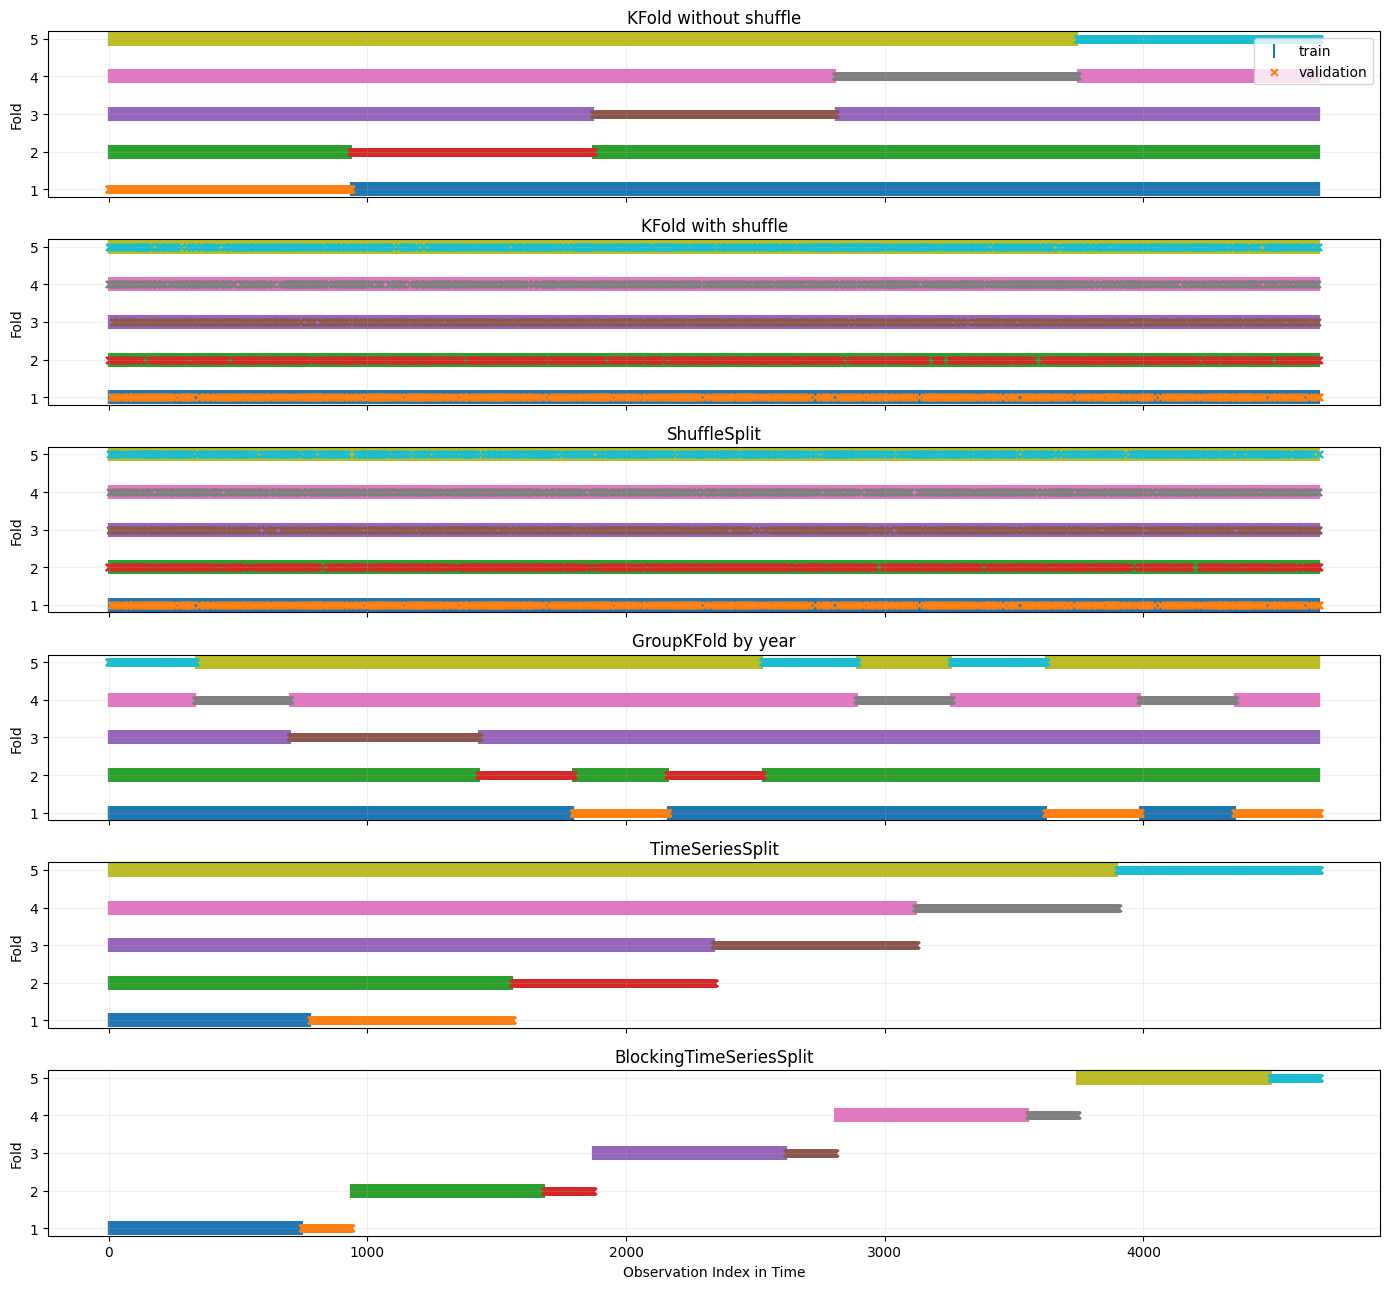

In [8]:
fig, axes = plt.subplots(len(cv_methods), 1, figsize=(14, 13), sharex=True)

for ax, method_name in zip(axes, cv_methods):
    splits = get_splits(method_name)

    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        ax.scatter(
            train_idx,
            np.full(len(train_idx), fold),
            marker="|",
            s=110,
            label="train" if fold == 1 else None,
        )
        ax.scatter(
            valid_idx,
            np.full(len(valid_idx), fold),
            marker="x",
            s=25,
            label="validation" if fold == 1 else None,
        )

    ax.set_title(method_name)
    ax.set_ylabel("Fold")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Observation Index in Time")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

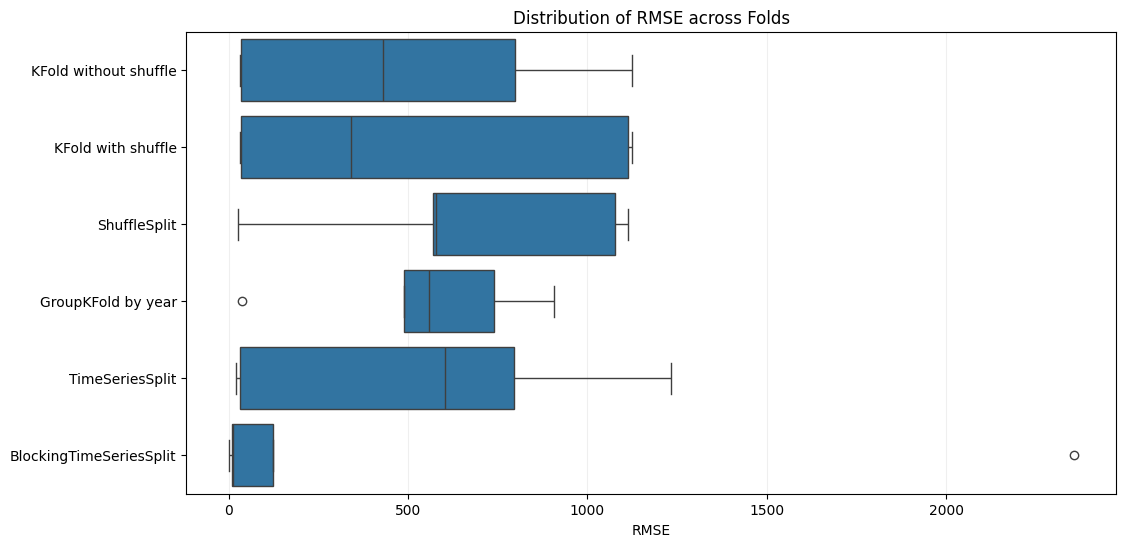

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=fold_results, x="RMSE", y="Method")
plt.title("Distribution of RMSE across Folds")
plt.xlabel("RMSE")
plt.ylabel("")
plt.grid(axis="x", alpha=0.2)
plt.show()

## 6. Final Out-of-Time Evaluation

After comparing the cross-validation schemes, the linear regression model is trained on the entire development set and evaluated once on the final 20% hold-out data.

In [10]:
final_model = clone(model)
final_model.fit(X_dev, y_dev)
holdout_pred = final_model.predict(X_holdout)

holdout_rmse = mean_squared_error(y_holdout, holdout_pred) ** 0.5
holdout_mae = mean_absolute_error(y_holdout, holdout_pred)
holdout_r2 = r2_score(y_holdout, holdout_pred)

holdout_metrics = pd.DataFrame([{
    "RMSE": holdout_rmse,
    "MAE": holdout_mae,
    "R2": holdout_r2,
}])

holdout_metrics.round(4)

,RMSE,MAE,R2
0,1770.2861,169.6777,0.9947


In [11]:
comparison = summary.copy()
comparison["Holdout_RMSE"] = holdout_rmse
comparison["|CV_RMSE - Holdout_RMSE|"] = (
    comparison["RMSE_mean"] - holdout_rmse
).abs()

comparison = comparison.sort_values(
    "|CV_RMSE - Holdout_RMSE|"
).reset_index(drop=True)

comparison.round(4)

,Method,Folds,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Temporal_order_rate,Holdout_RMSE,|CV_RMSE - Holdout_RMSE|
0,ShuffleSplit,5,673.5441,445.7789,52.6016,28.0277,9.967000e-01,3.100000e-03,0.0,1770.2861,1096.7420
1,GroupKFold by year,5,545.7437,328.3816,37.4297,13.8026,8.592000e-01,2.982000e-01,0.0,1770.2861,1224.5424
2,TimeSeriesSplit,5,536.4786,518.8663,44.8135,39.7578,9.922000e-01,2.100000e-03,100.0,1770.2861,1233.8075
3,KFold with shuffle,5,528.9938,553.2893,44.2807,32.1919,9.972000e-01,3.500000e-03,0.0,1770.2861,1241.2923
4,BlockingTimeSeriesSplit,5,500.8748,1038.7387,107.3859,182.6861,-1.418419e+26,3.139826e+26,100.0,1770.2861,1269.4113
5,KFold without shuffle,5,483.9535,479.3607,40.8911,22.5119,-6.113900e+00,1.588490e+01,0.0,1770.2861,1286.3325


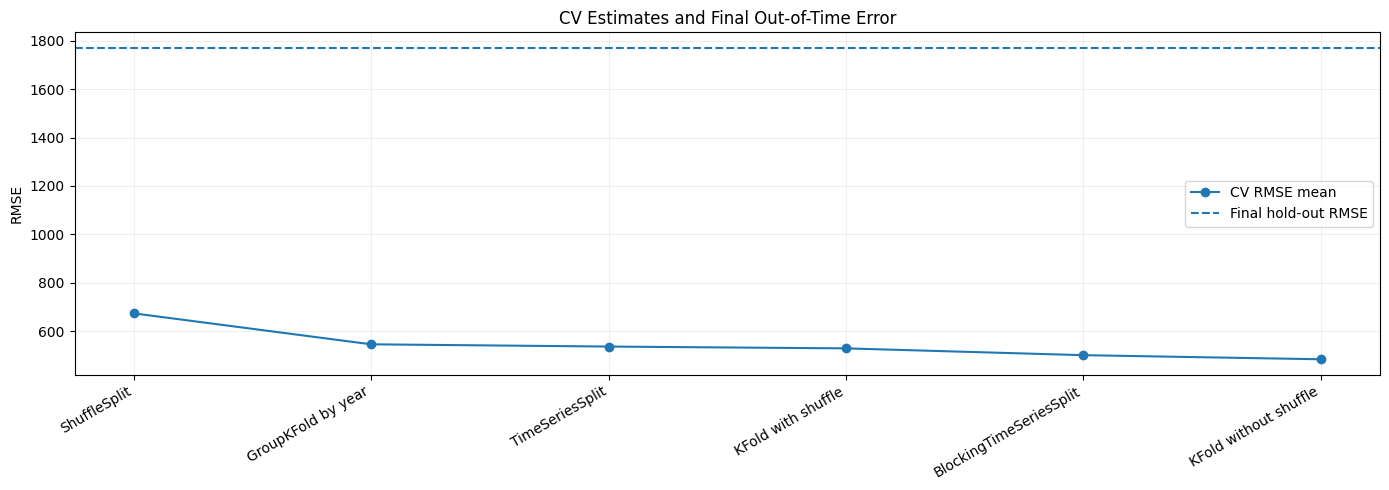

In [12]:
plt.figure(figsize=(14, 5))
plt.plot(
    comparison["Method"],
    comparison["RMSE_mean"],
    marker="o",
    label="CV RMSE mean",
)
plt.axhline(
    holdout_rmse,
    linestyle="--",
    label="Final hold-out RMSE",
)
plt.xticks(rotation=30, ha="right")
plt.ylabel("RMSE")
plt.title("CV Estimates and Final Out-of-Time Error")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Conclusions

- All schemes were applied to the same linear regression model and the same set of features.
- `KFold` with shuffling and `ShuffleSplit` violate the temporal order: future observations can end up in the training set relative to the validation fold (data leakage from the future).
- `KFold` without shuffling preserves contiguous validation folds, but training for certain folds still includes observations from later points in time.
- `GroupKFold` by year avoids splitting the same year across train and validation sets, but by itself does not guarantee chronological ordering.
- `TimeSeriesSplit` strictly preserves temporal order and uses an expanding training window.
- `BlockingTimeSeriesSplit` also respects the forward direction of time, but uses non-overlapping, independent time blocks.
- For next-day forecasting, temporal methods are the primary correct schemes, as they accurately simulate real-world production deployment.
- The final performance assessment is performed strictly on an independent out-of-time holdout set that was never seen during cross-validation.
- Cross-validation schemes should be evaluated not only on mean metric values, but also on variance across folds and alignment with the actual operational setting of the model.